# 01 · Exploratory data analysis

**Data:** the Spotify Tracks Dataset (114,000 rows, 114 genres, BSD licence, mirrored on
[HuggingFace](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset) and Kaggle).
Each row is a track with metadata, a popularity score (0-100), a genre label and Spotify's
audio analysis (danceability, energy, valence, ...).

This notebook looks for the things that decide how the recommender should be built:
duplicates, label structure, skewed features, measurement errors and how genres differ.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
from src.data.load import load_raw

df = load_raw()
print(df.shape)
df.head()

(114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 1. Data quality: nulls, duplicates and what a row really is

In [2]:
print("Nulls:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print(f"Rows: {len(df):,}   distinct track ids: {df.track_id.nunique():,}")
listed = df.groupby("track_id").track_genre.nunique()
print(f"Track ids listed under more than one genre: {(listed > 1).sum():,} ({(listed > 1).mean():.1%})")
print(f"Most genres for one track: {listed.max()}")
same_song = df.drop_duplicates("track_id").duplicated(["track_name", "artists"]).sum()
print(f"Same title + artist under different track ids (single vs album vs compilation): {same_song:,}")

Nulls: {'artists': 1, 'album_name': 1, 'track_name': 1}
Rows: 114,000   distinct track ids: 89,741
Track ids listed under more than one genre: 16,299 (18.2%)
Most genres for one track: 9


Same title + artist under different track ids (single vs album vs compilation): 8,397


**Finding 1 - a row is a (track, genre) pair, not a track.** About 18% of track ids appear
under several genres. The original pipeline dropped duplicates by title + artist and kept
whichever genre came first, which throws away real multi-genre labels (a track listed under both
*indie* and *folk* is information). Notebook 02 keeps every genre per track as a multi-label list.

**Finding 2 - the same song exists under several ids** (single, album, deluxe, compilation). If we keep
them all, the recommender will happily recommend "Blinding Lights" to someone who already has
"Blinding Lights", so they are merged.

In [3]:
multi = df[df.track_id.isin(listed[listed > 1].index)]
pairs = (multi.groupby("track_id").track_genre.apply(lambda s: tuple(sorted(s)))
              .loc[lambda s: s.map(len) == 2].value_counts().head(12))
pairs.rename("tracks").to_frame()

,tracks
track_genre,
"(dub, dubstep)",619
"(singer-songwriter, songwriter)",507
"(punk, punk-rock)",295
"(brazil, gospel)",295
"(chill, sad)",250
"(indie, indie-pop)",249
"(minimal-techno, techno)",233
"(deep-house, groove)",210
"(dancehall, j-dance)",194


The most common genre pairs make musical sense, which means genre co-listing is a useful signal for how close two genres are. Notebook 03 turns it into a learned genre map.

## 2. Measurement errors in the audio analysis

tempo == 0: 157    time_signature == 0: 163    duration < 30s: 17


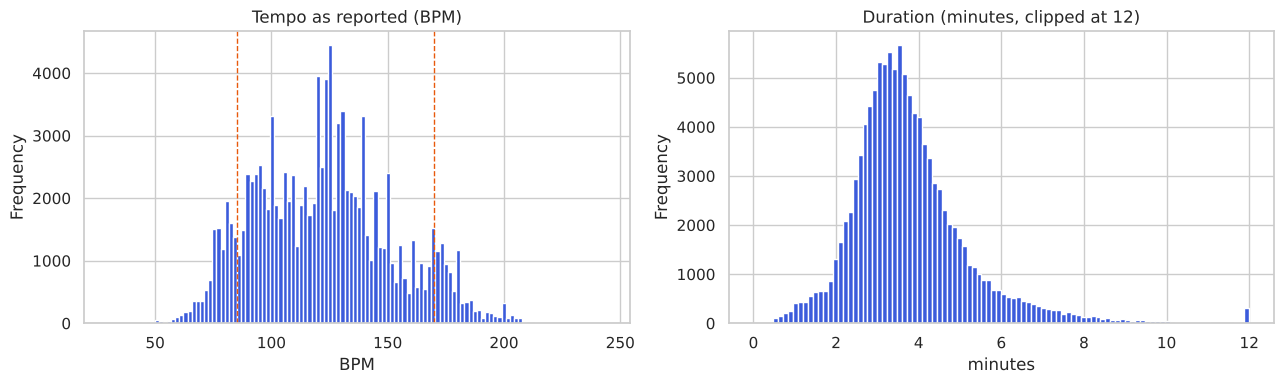

In [4]:
print("tempo == 0:", (df.tempo == 0).sum(), "   time_signature == 0:", (df.time_signature == 0).sum(),
      "   duration < 30s:", (df.duration_ms < 30_000).sum())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.tempo[df.tempo > 0].plot.hist(bins=120, ax=axes[0], color="#3b5bdb")
axes[0].set(title="Tempo as reported (BPM)", xlabel="BPM")
for bpm in (85, 170):
    axes[0].axvline(bpm, color="#e8590c", ls="--", lw=1)
(df.duration_ms / 60000).clip(upper=12).plot.hist(bins=100, ax=axes[1], color="#3b5bdb")
axes[1].set(title="Duration (minutes, clipped at 12)", xlabel="minutes")
plt.tight_layout(); plt.savefig(FIG / "01_tempo_duration.png"); plt.show()

**Finding 3 - tempo has octave errors.** Beat trackers often report half or double the felt
tempo, so a 85 BPM groove and a 170 BPM drum-and-bass track can be the same feel, and the same song
can be read either way. The distribution has a long shoulder above 160 that mirrors the 80-90 hump.
Notebook 03 folds tempo into one octave. Tracks with tempo 0 or time signature 0 are failed analyses
and are dropped.

## 3. Feature distributions

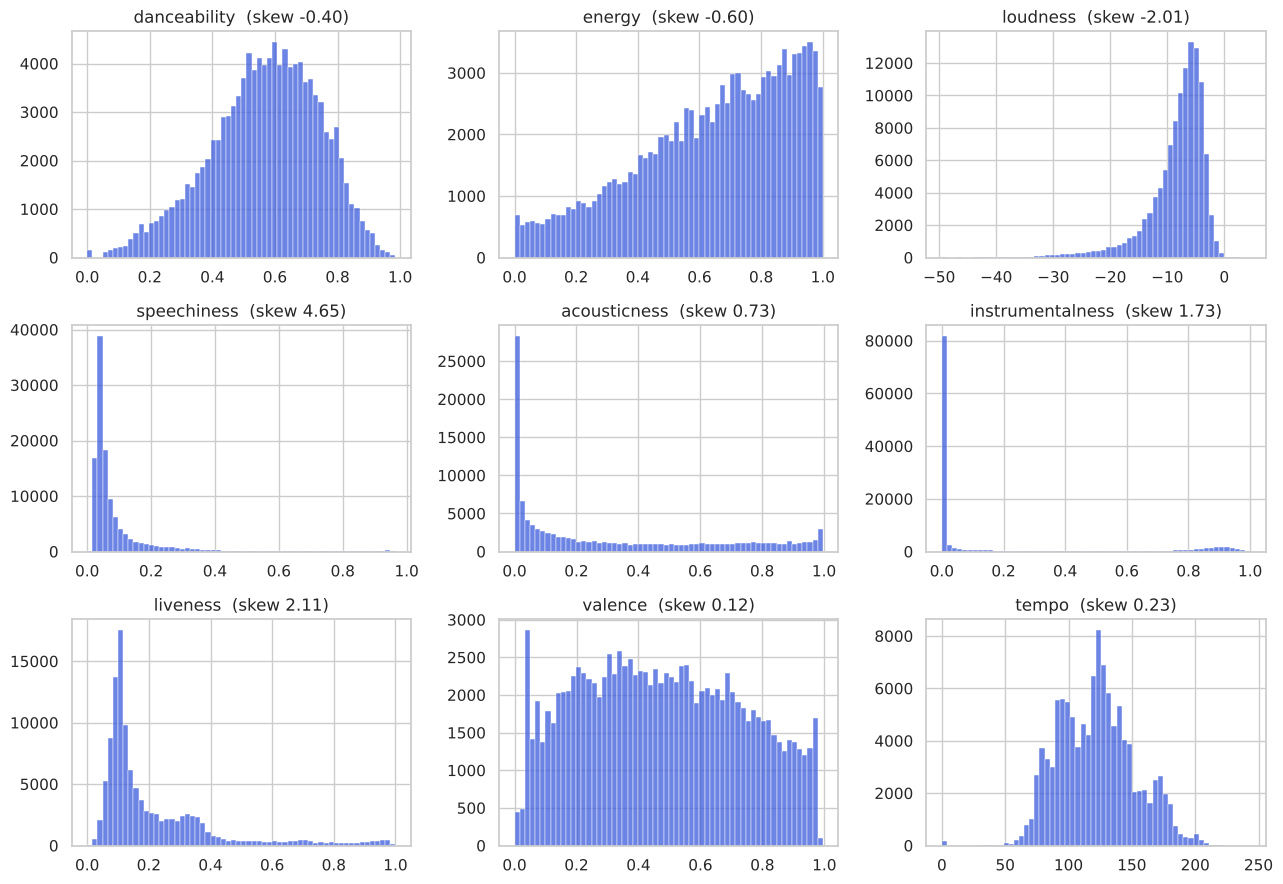

In [5]:
feats = config.AUDIO_FEATURES
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, f in zip(axes.ravel(), feats):
    sns.histplot(df[f], bins=60, ax=ax, color="#3b5bdb", edgecolor=None)
    ax.set(title=f"{f}  (skew {df[f].skew():.2f})", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "01_feature_distributions.png"); plt.show()

**Finding 4 - four features are far from bell-shaped.** `speechiness`, `instrumentalness` and
`liveness` pile up near 0 with long tails (instrumentalness is close to a yes/no "is this
instrumental" with most mass at 0), and `acousticness` is U-shaped, with peaks at both ends. On a raw scale a distance metric barely notices
differences in the crowded low end, where most tracks are. Notebook 03 maps them through a
quantile transform. `loudness` has a long quiet tail (ambient, classical) that is clipped.

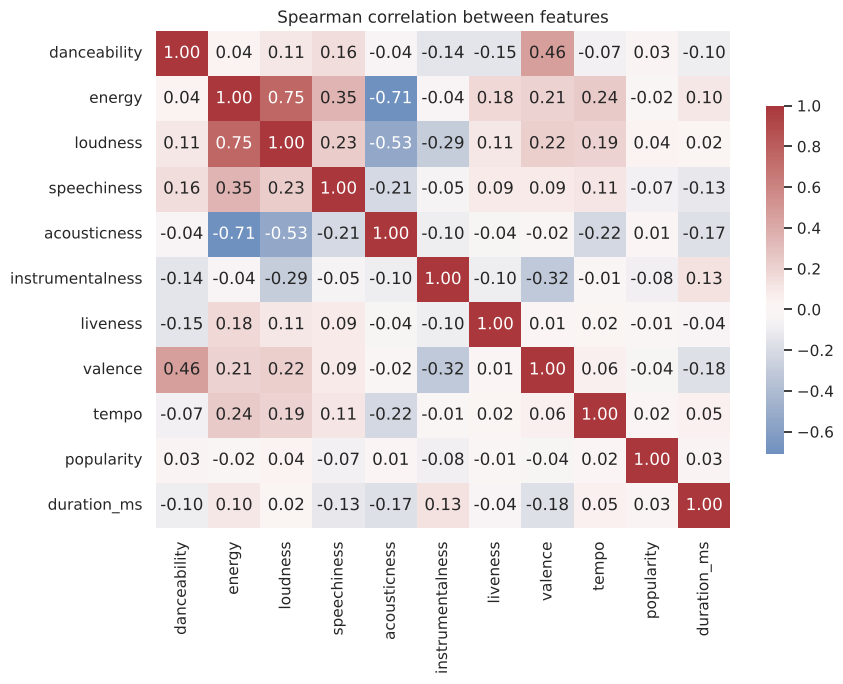

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df[feats + ["popularity", "duration_ms"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Spearman correlation between features")
plt.tight_layout(); plt.savefig(FIG / "01_feature_correlations.png"); plt.show()

**Finding 5 - energy, loudness and acousticness are largely one axis seen three ways**
(energy vs loudness ρ ≈ 0.75, energy vs acousticness ρ ≈ -0.71).
Giving each full weight in a distance would count "how intense is this" three times. The feature
weights in notebook 03 keep energy strong and turn loudness down. Popularity correlates with no audio
feature, so "what sounds good" and "what is popular" are separate signals; the recommender needs
listening data, not audio alone, to know what people actually add.

## 4. Popularity

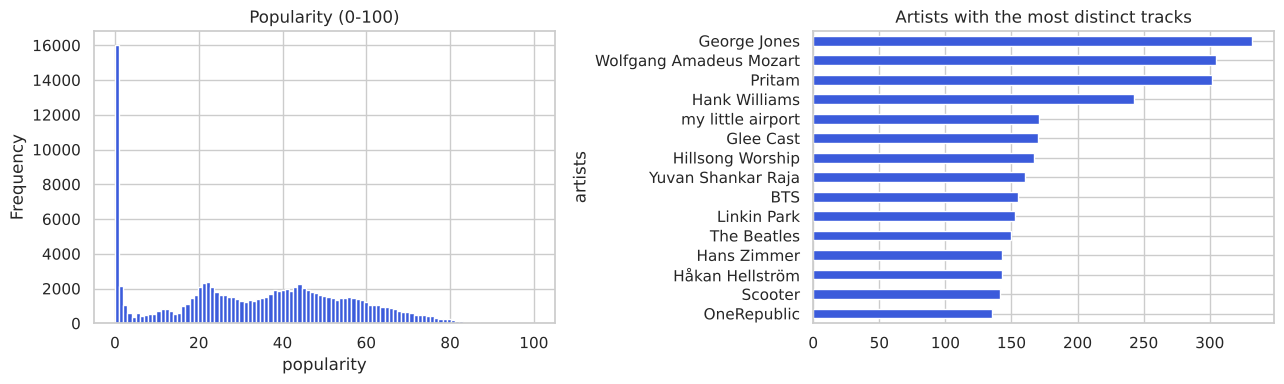

popularity == 0: 14.1% of rows


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.popularity.plot.hist(bins=101, ax=axes[0], color="#3b5bdb")
axes[0].set(title="Popularity (0-100)", xlabel="popularity")
top_artists = df.drop_duplicates("track_id").artists.str.split(";").str[0].value_counts().head(15)
top_artists[::-1].plot.barh(ax=axes[1], color="#3b5bdb")
axes[1].set(title="Artists with the most distinct tracks")
plt.tight_layout(); plt.savefig(FIG / "01_popularity_artists.png"); plt.show()
print(f"popularity == 0: {(df.popularity == 0).mean():.1%} of rows")

Popularity has a spike at 0 (about 14% of rows, many of them duplicate releases of a song
that is popular under another id) and a long tail. A few artists contribute a lot of tracks
(George Jones, Mozart, Pritam and Hank Williams each have 240+), which matters for diversity: an unconstrained
recommender can fill a list with one artist, so the console app caps tracks per artist.

## 5. How genres sound

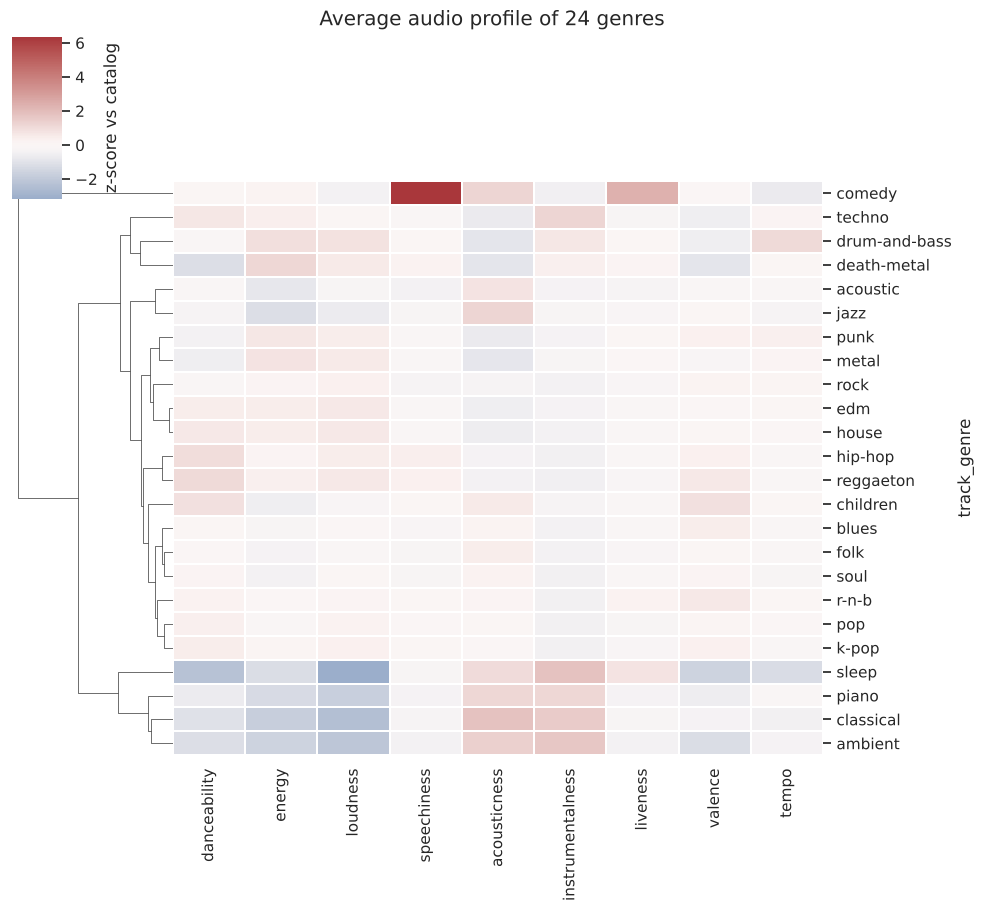

In [8]:
z = (df[feats] - df[feats].mean()) / df[feats].std()
profile = z.groupby(df.track_genre).mean()
sample = ["classical", "ambient", "piano", "sleep", "acoustic", "folk", "jazz", "blues", "soul", "r-n-b",
          "hip-hop", "reggaeton", "pop", "k-pop", "edm", "house", "techno", "drum-and-bass", "rock",
          "punk", "metal", "death-metal", "comedy", "children"]
g = sns.clustermap(profile.loc[sample], cmap="vlag", center=0, figsize=(10, 9), col_cluster=False,
                   cbar_kws={"label": "z-score vs catalog"}, linewidths=.3)
g.fig.suptitle("Average audio profile of 24 genres", y=1.01)
g.savefig(FIG / "01_genre_profiles.png"); plt.show()

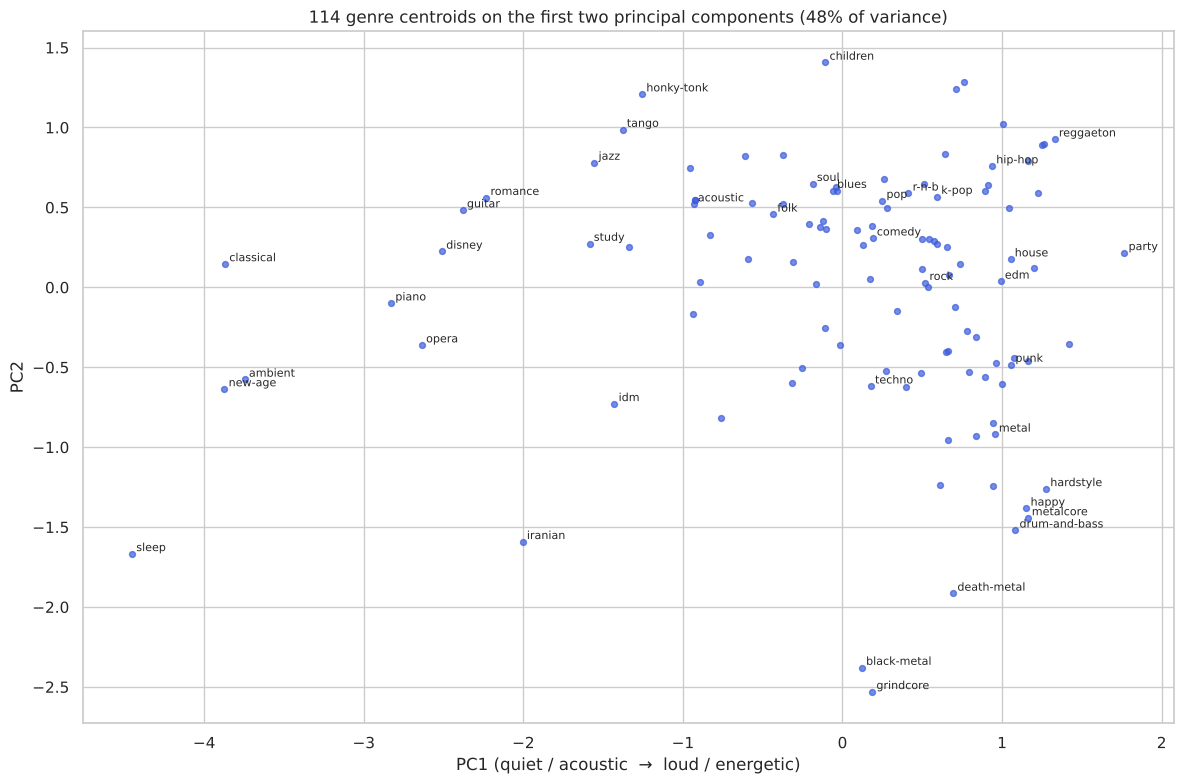

,acousticness,instrumentalness,liveness,speechiness,tempo,danceability,valence,energy,loudness
PC1 loading,-0.44,-0.28,0.09,0.1,0.19,0.25,0.3,0.51,0.52


In [9]:
from sklearn.decomposition import PCA
pca = PCA(2).fit(z)
cent = pca.transform(profile)
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(cent[:, 0], cent[:, 1], s=18, color="#3b5bdb", alpha=.7)
for (x, y), name in zip(cent, profile.index):
    if name in sample or np.hypot(x, y) > 1.6:
        ax.annotate(name, (x, y), fontsize=8, xytext=(3, 2), textcoords="offset points")
ax.set(title=f"114 genre centroids on the first two principal components "
             f"({pca.explained_variance_ratio_.sum():.0%} of variance)",
       xlabel="PC1 (quiet / acoustic  →  loud / energetic)", ylabel="PC2")
plt.tight_layout(); plt.savefig(FIG / "01_genre_pca.png"); plt.show()
pd.Series(pca.components_[0], feats).sort_values().round(2).to_frame("PC1 loading").T

Genres separate clearly along an intensity axis (PC1: energy and loudness against acousticness)
and a vocal/rhythmic axis, but many genres overlap: pop, k-pop, dance and latin sit almost on top of
each other. Audio features alone cannot tell those scenes apart, which is why genre labels and
listening data both get their own block in the model.

## Summary

| Finding | What the pipeline does about it |
|---|---|
| 18% of tracks carry several genres | keep all genres as a multi-label list (02) |
| same song under several ids | merge by normalised title + main artist (02) |
| tempo octave errors, tempo 0 / time signature 0 | fold tempo into one octave (03), drop failed analyses (02) |
| four heavily skewed features | quantile transform to a normal shape (03) |
| energy / loudness / acousticness redundant | feature weights, loudness down-weighted (03) |
| genres overlap in audio space | learned genre embedding from co-listing + sound (03) |
| popularity independent of audio | collaborative filtering on listening data (05) |
| no user or playlist data in the dataset | simulated listeners with a documented taste model (04) |